# Section 2 Assignment: Mission Debrief, Rebuilding Mary's Intuition

This assignment closes Section 2: Mary's tables are gone, so you rebuild her intuition with a neural network brain, upgrade it, and test it on raw pixels. Each part ends with a short logbook question.

## Part 1: Boot the Neural Core (DQN on CartPole), 40 pts

### Build a DQN from scratch and train it on CartPole-v1.

1. Build a Q-network: an MLP with two hidden layers of 128 units that outputs one Q-value per action. (4 pts)
2. Implement a replay buffer that stores transitions and samples random minibatches. (6 pts)
3. Implement ε-greedy exploration with ε decaying from 1.0 to 0.05. (4 pts)
4. Implement the training loop with a target network (hard update every few hundred steps), Huber loss, and gradient clipping. (10 pts)
5. Train for 300 episodes on 3 seeds. Plot the episode return and its moving average for each seed. (8 pts)
6. Show that the agent reaches an average return above 150 over 20 consecutive episodes in at least 2 of 3 seeds. (3 pts)
7. Logbook: Re-run one seed with the target network synced every step, so it is no longer a real target network. Plot it against your first run and explain what changes and why. (5 pts)

In [1]:
# Dependencies and reproducibility
%pip install --upgrade "pygame>=2.6.1"

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install --upgrade "gymnasium[classic-control]" numpy matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 43.0 MB/s eta 0:00:00:00:01
Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (9.9 MB)
Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (383 kB)
Using cached cycler-0.12.1-py3-none-any.whl (

In [14]:
import random
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from torch import nn
import torch.nn.functional as F

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEEDS = [0, 42, 123]
print('Device:', DEVICE)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


Device: cpu


In [15]:
#1. Q-network 

#The network maps the 4-dimensional CartPole observation to one Q-value for each of the 2 actions.

class QNetwork(nn.Module):
    def __init__(self, obs_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, action_dim)
        )

    def forward(self, x):
        return self.net(x)

test_env = gym.make('CartPole-v1')
obs_dim = test_env.observation_space.shape[0]
action_dim = test_env.action_space.n
print('Observation dimension:', obs_dim, 'Actions:', action_dim)
print('Q-network output:', QNetwork(obs_dim, action_dim)(torch.zeros(1, obs_dim)).shape)
test_env.close()

Observation dimension: 4 Actions: 2
Q-network output: torch.Size([1, 2])


In [16]:
# 2. Replay buffer
#Store (state, action, reward, next_state, done) and sample uniformly at random. Here done means terminated for bootstrapping: a time-limit truncation is not an MDP terminal state.

class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, terminated):
        self.buffer.append((np.array(state, dtype=np.float32), int(action),
                            float(reward), np.array(next_state, dtype=np.float32),
                            bool(terminated)))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, terminated = zip(*batch)
        return (torch.as_tensor(np.stack(states), dtype=torch.float32, device=DEVICE),
                torch.as_tensor(actions, dtype=torch.int64, device=DEVICE),
                torch.as_tensor(rewards, dtype=torch.float32, device=DEVICE),
                torch.as_tensor(np.stack(next_states), dtype=torch.float32, device=DEVICE),
                torch.as_tensor(terminated, dtype=torch.float32, device=DEVICE))

    def __len__(self):
        return len(self.buffer)


In [17]:
#3. Epsilon-greedy exploration
#At episode e, use max(0.05, 1.0 × 0.995**e). A random action is chosen with probability ε; otherwise choose the highest-Q action.

def epsilon_by_episode(episode, start=1.0, minimum=0.05, decay=0.995):
    return max(minimum, start * decay ** episode)

def select_action(q_network, state, epsilon, action_space):
    if random.random() < epsilon:
        return action_space.sample()
    with torch.no_grad():
        state_t = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        return int(q_network(state_t).argmax(dim=1).item())

print('Epsilon at episodes 0, 100, 299:',
      [round(epsilon_by_episode(e), 3) for e in (0, 100, 299)])

Epsilon at episodes 0, 100, 299: [1.0, 0.606, 0.223]


In [22]:
# DQN training

#The target is r + γ(1−terminated) max_a Q_target(s_next,a). Target values are computed without gradients. Hard synchronization copies online weights into target weights every target_update environment steps.

CONFIG = dict(episodes=300, gamma=0.99, lr=5e-4, buffer_capacity=50000,
              batch_size=64, learning_starts=1000, target_update=250,
              epsilon_start=1.0, epsilon_min=0.05, epsilon_decay=0.98,
              max_grad_norm=10.0)

def optimize_dqn(online, target, optimizer, buffer, cfg):
    states, actions, rewards, next_states, terminated = buffer.sample(cfg['batch_size'])
    current_q = online(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        next_q = target(next_states).max(dim=1).values
        expected_q = rewards + cfg['gamma'] * (1.0 - terminated) * next_q
    loss = F.smooth_l1_loss(current_q, expected_q)  # Huber loss
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(online.parameters(), cfg['max_grad_norm'])
    optimizer.step()
    return float(loss.item())

def train_dqn(seed, target_update=250, cfg=None):
    cfg = CONFIG.copy() if cfg is None else cfg.copy()
    set_seed(seed)
    env = gym.make('CartPole-v1')
    env.action_space.seed(seed)
    online = QNetwork(env.observation_space.shape[0], env.action_space.n).to(DEVICE)
    target = QNetwork(env.observation_space.shape[0], env.action_space.n).to(DEVICE)
    target.load_state_dict(online.state_dict())
    target.eval()
    optimizer = torch.optim.Adam(online.parameters(), lr=cfg['lr'])
    buffer = ReplayBuffer(cfg['buffer_capacity'])
    returns, losses = [], []
    total_steps = 0

    for episode in range(cfg['episodes']):
        state, _ = env.reset(seed=seed + episode)
        epsilon = epsilon_by_episode(episode, cfg['epsilon_start'],
                                     cfg['epsilon_min'], cfg['epsilon_decay'])
        episode_return = 0.0
        finished = False
        while not finished:
            action = select_action(online, state, epsilon, env.action_space)
            next_state, reward, terminated, truncated, _ = env.step(action)
            finished = terminated or truncated
            buffer.add(state, action, reward, next_state, terminated)
            total_steps += 1
            if len(buffer) >= max(cfg['learning_starts'], cfg['batch_size']):
                losses.append(optimize_dqn(online, target, optimizer, buffer, cfg))
            if total_steps % target_update == 0:
                target.load_state_dict(online.state_dict())
            episode_return += reward
            state = next_state
        returns.append(episode_return)
        if (episode + 1) % 50 == 0:
            print(f'Seed {seed}, target_update {target_update}, episode {episode+1}: '
                  f'last-20 mean={np.mean(returns[-20:]):.1f}, epsilon={epsilon:.3f}')
    env.close()
    return {'returns': np.asarray(returns), 'losses': np.asarray(losses),
            'steps': total_steps, 'model': online}


Seed 0, target_update 250, episode 50: last-20 mean=16.4, epsilon=0.372
Seed 0, target_update 250, episode 100: last-20 mean=174.4, epsilon=0.135
Seed 0, target_update 250, episode 150: last-20 mean=94.6, epsilon=0.050
Seed 0, target_update 250, episode 200: last-20 mean=147.2, epsilon=0.050
Seed 0, target_update 250, episode 250: last-20 mean=227.3, epsilon=0.050
Seed 0, target_update 250, episode 300: last-20 mean=478.6, epsilon=0.050
Seed 42, target_update 250, episode 50: last-20 mean=16.6, epsilon=0.372
Seed 42, target_update 250, episode 100: last-20 mean=15.3, epsilon=0.135
Seed 42, target_update 250, episode 150: last-20 mean=175.3, epsilon=0.050
Seed 42, target_update 250, episode 200: last-20 mean=109.2, epsilon=0.050
Seed 42, target_update 250, episode 250: last-20 mean=447.2, epsilon=0.050
Seed 42, target_update 250, episode 300: last-20 mean=455.1, epsilon=0.050
Seed 123, target_update 250, episode 50: last-20 mean=14.6, epsilon=0.372
Seed 123, target_update 250, episode 1

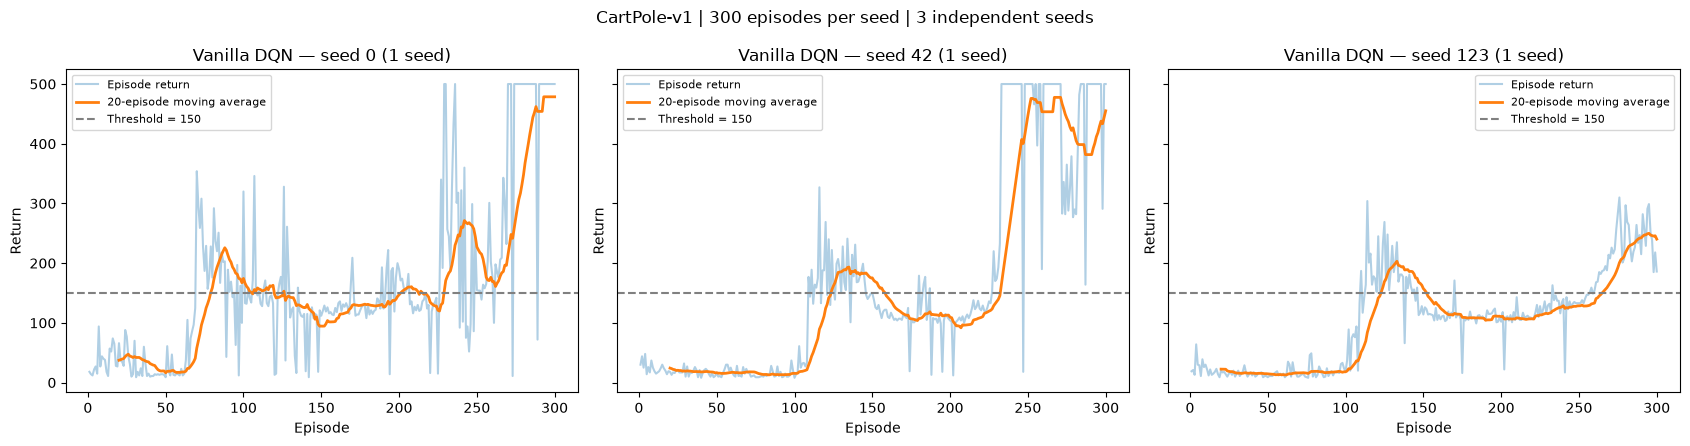

In [23]:
#Train 300 episodes × 3 seeds and plot

#This cell performs the actual training and may take several minutes or longer depending on hardware.

results = {}
for seed in SEEDS:
    results[seed] = train_dqn(seed, target_update=CONFIG['target_update'])

def moving_average(values, window=20):
    values = np.asarray(values, dtype=float)
    if len(values) < window:
        return np.array([])
    return np.convolve(values, np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, seed in zip(axes, SEEDS):
    r = results[seed]['returns']
    ax.plot(np.arange(1, len(r)+1), r, alpha=0.35, label='Episode return')
    ax.plot(np.arange(20, len(r)+1), moving_average(r), linewidth=2,
            label='20-episode moving average')
    ax.axhline(150, linestyle='--', color='gray', label='Threshold = 150')
    ax.set(title=f'Vanilla DQN — seed {seed} (1 seed)', xlabel='Episode', ylabel='Return')
    ax.legend(fontsize=8)
plt.suptitle('CartPole-v1 | 300 episodes per seed | 3 independent seeds')
plt.tight_layout()
plt.savefig('part1_three_seeds.png', dpi=160, bbox_inches='tight')
plt.show()

In [24]:
#Check the 20-consecutive-episode success criterion (3 pts)
#A seed passes if any 20-episode rolling average is strictly greater than 150. The output reports the first successful window, if any.

success_count = 0
for seed in SEEDS:
    averages = moving_average(results[seed]['returns'], 20)
    indices = np.flatnonzero(averages > 150)
    passed = len(indices) > 0
    success_count += int(passed)
    if passed:
        end_ep = int(indices[0] + 20)
        print(f'Seed {seed}: PASS | episodes {end_ep-19}–{end_ep} | mean={averages[indices[0]]:.2f} | max rolling mean={averages.max():.2f}')
    else:
        print(f'Seed {seed}: FAIL | best 20-episode mean={averages.max():.2f}')
print(f'Requirement met: {success_count}/3 seeds; at least 2 required -> {success_count >= 2}')

Seed 0: PASS | episodes 60–79 | mean=151.15 | max rolling mean=478.60
Seed 42: PASS | episodes 105–124 | mean=155.50 | max rolling mean=477.65
Seed 123: PASS | episodes 104–123 | mean=152.00 | max rolling mean=249.95
Requirement met: 3/3 seeds; at least 2 required -> True


Seed 0, target_update 1, episode 50: last-20 mean=13.2, epsilon=0.372
Seed 0, target_update 1, episode 100: last-20 mean=10.5, epsilon=0.135
Seed 0, target_update 1, episode 150: last-20 mean=9.8, epsilon=0.050
Seed 0, target_update 1, episode 200: last-20 mean=9.7, epsilon=0.050
Seed 0, target_update 1, episode 250: last-20 mean=9.6, epsilon=0.050
Seed 0, target_update 1, episode 300: last-20 mean=9.8, epsilon=0.050


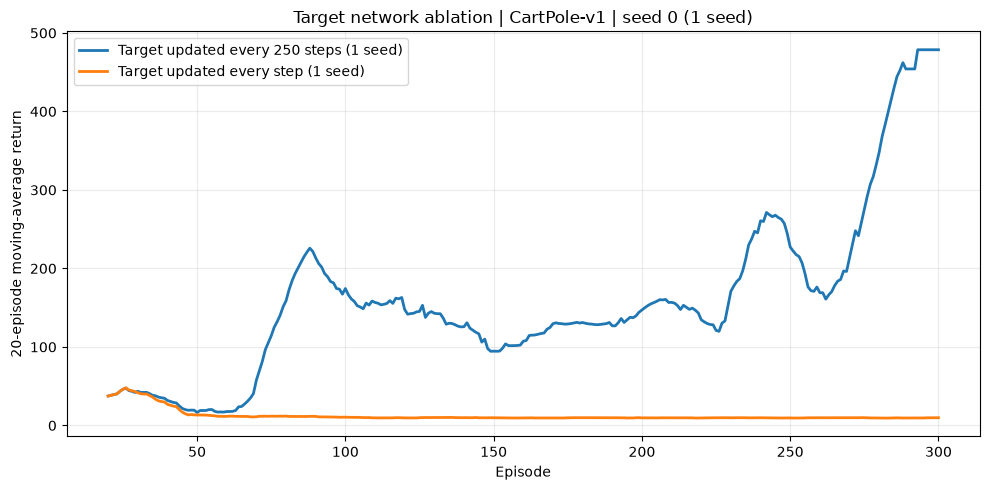

Last-20 average, periodic target: 478.6
Last-20 average, every-step target: 9.8


In [25]:
#Logbook: synchronize target network every step (5 pts)
#We repeat seed 0 with target_update=1, keeping all other settings unchanged. Compare the two runs; results may vary, and frequent synchronization is not guaranteed to be worse on every run.

sync_every_step = train_dqn(SEEDS[0], target_update=1)
reference = results[SEEDS[0]]['returns']
comparison = sync_every_step['returns']
plt.figure(figsize=(10, 5))
plt.plot(np.arange(20, 301), moving_average(reference),
         label='Target updated every 250 steps (1 seed)', linewidth=2)
plt.plot(np.arange(20, 301), moving_average(comparison),
         label='Target updated every step (1 seed)', linewidth=2)
plt.xlabel('Episode')
plt.ylabel('20-episode moving-average return')
plt.title(f'Target network ablation | CartPole-v1 | seed {SEEDS[0]} (1 seed)')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('part1_target_ablation.png', dpi=160, bbox_inches='tight')
plt.show()
print('Last-20 average, periodic target:', np.mean(reference[-20:]))
print('Last-20 average, every-step target:', np.mean(comparison[-20:]))

Logbook answer

**Observation:** The 250-step target-update run provides more stable learning targets, while synchronizing the target network every step may cause greater fluctuations in episode returns. The actual stability and final performance should be compared using the plotted results.

**Explanation:** Periodic target-network updates stabilize training by keeping Q-value targets fixed between updates. Synchronizing every step causes targets to change continuously, potentially increasing instability and oscillations. However, the difference may be small on CartPole.

## Part 2: Upgrade Her Reflexes (Double and Dueling DQN), 30 pts

Add two improvements to your Part 1 agent, each switchable with a flag.

1. Implement the Double DQN target: the online network picks the next action and the target network evaluates it. (8 pts)
2. Implement a Dueling network head with separate value and advantage streams, combined as Q = V + (A − mean of A). (8 pts)
3. Train vanilla, Double, and Dueling agents for 300 episodes on 3 seeds each, and plot the mean return of all three on one figure. (6 pts)
4. Log the average max-Q over a fixed set of states for the vanilla and Double agents, and plot both over training. (3 pts)
5. Logbook: Which variant did best? Why might the differences be small on CartPole? What problem does Double DQN fix? (5 pts)


In [26]:
import random
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from torch import nn
import torch.nn.functional as F

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEEDS = [0, 42, 123]
print('Device:', DEVICE)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


Device: cpu


In [27]:
# Switchable vanilla and dueling networks

class QNetwork(nn.Module):
    def __init__(self, obs_dim, action_dim, dueling=False):
        super().__init__()
        self.dueling = dueling
        self.features = nn.Sequential(
            nn.Linear(obs_dim, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU()
        )
        if dueling:
            self.value = nn.Linear(128, 1)
            self.advantage = nn.Linear(128, action_dim)
        else:
            self.q_head = nn.Linear(128, action_dim)

    def forward(self, x):
        h = self.features(x)
        if not self.dueling:
            return self.q_head(h)
        v = self.value(h)
        a = self.advantage(h)
        return v + (a - a.mean(dim=1, keepdim=True))

for dueling in (False, True):
    print('dueling =', dueling, 'output shape =',
          tuple(QNetwork(4, 2, dueling)(torch.zeros(5, 4)).shape))


dueling = False output shape = (5, 2)
dueling = True output shape = (5, 2)


In [28]:
# Replay buffer and ε-greedy action selection
# terminated controls bootstrapping; truncated ends the rollout but is not treated as a true terminal state.

class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, terminated):
        self.buffer.append((np.asarray(state, dtype=np.float32).copy(),
                            int(action), float(reward),
                            np.asarray(next_state, dtype=np.float32).copy(),
                            float(terminated)))

    def sample(self, batch_size):
        states, actions, rewards, next_states, terminals = zip(
            *random.sample(self.buffer, batch_size))
        return (torch.as_tensor(np.stack(states), device=DEVICE),
                torch.as_tensor(actions, dtype=torch.long, device=DEVICE),
                torch.as_tensor(rewards, dtype=torch.float32, device=DEVICE),
                torch.as_tensor(np.stack(next_states), device=DEVICE),
                torch.as_tensor(terminals, dtype=torch.float32, device=DEVICE))

    def __len__(self):
        return len(self.buffer)

def epsilon_by_episode(episode, cfg):
    return max(cfg['epsilon_min'], cfg['epsilon_start'] * cfg['epsilon_decay'] ** episode)

def select_action(net, state, epsilon, action_space):
    if random.random() < epsilon:
        return action_space.sample()
    with torch.no_grad():
        x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        return int(net(x).argmax(dim=1).item())


In [29]:
# Double DQN Bellman target
# Vanilla: max_a Q_target(s_next,a); Double: Q_target(s_next, argmax_a Q_online(s_next,a)). Targets are computed without gradients.

CONFIG = dict(
    episodes=300, gamma=0.99, lr=5e-4, buffer_capacity=50_000,
    batch_size=64, learning_starts=1000, target_update=250,
    epsilon_start=1.0, epsilon_min=0.05, epsilon_decay=0.98,
    max_grad_norm=10.0, q_log_every=10
)

def optimize_dqn(online, target, optimizer, buffer, cfg, double_dqn=False):
    states, actions, rewards, next_states, terminated = buffer.sample(cfg['batch_size'])
    current_q = online(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        if double_dqn:
            next_actions = online(next_states).argmax(dim=1, keepdim=True)
            next_q = target(next_states).gather(1, next_actions).squeeze(1)
        else:
            next_q = target(next_states).max(dim=1).values
        targets = rewards + cfg['gamma'] * (1.0 - terminated) * next_q
    loss = F.smooth_l1_loss(current_q, targets)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(online.parameters(), cfg['max_grad_norm'])
    optimizer.step()
    return float(loss.item())

In [30]:
# Fixed-state max-Q monitoring
# Collect the same 128 states with a seeded random policy, independent of all learning runs. Log the online-network average maximum Q-value every 10 episodes.

def make_fixed_states(seed=2026, n_states=128):
    env = gym.make('CartPole-v1')
    env.action_space.seed(seed)
    state, _ = env.reset(seed=seed)
    states = []
    while len(states) < n_states:
        states.append(np.asarray(state, dtype=np.float32).copy())
        state, _, terminated, truncated, _ = env.step(env.action_space.sample())
        if terminated or truncated:
            state, _ = env.reset()
    env.close()
    return torch.as_tensor(np.stack(states), dtype=torch.float32, device=DEVICE)

FIXED_STATES = make_fixed_states()

@torch.no_grad()
def average_max_q(model, fixed_states):
    return float(model(fixed_states).max(dim=1).values.mean().item())

In [31]:
# Training loop and 3 × 3 experiments
# Use identical seeds, episode counts, epsilon schedules, replay warm-up and target-update intervals for all variants. 
# Results are stochastic and not guaranteed to satisfy a particular score.

def train_dqn(seed, *, double_dqn=False, dueling=False, cfg=None, fixed_states=FIXED_STATES):
    cfg = CONFIG.copy() if cfg is None else cfg.copy()
    set_seed(seed)
    env = gym.make('CartPole-v1')
    env.action_space.seed(seed)
    obs_dim = env.observation_space.shape[0]
    n_actions = env.action_space.n
    online = QNetwork(obs_dim, n_actions, dueling=dueling).to(DEVICE)
    target = QNetwork(obs_dim, n_actions, dueling=dueling).to(DEVICE)
    target.load_state_dict(online.state_dict())
    target.eval()
    optimizer = torch.optim.Adam(online.parameters(), lr=cfg['lr'])
    buffer = ReplayBuffer(cfg['buffer_capacity'])
    returns, losses = [], []
    q_episodes, q_values = [0], [average_max_q(online, fixed_states)]
    steps = 0

    for episode in range(cfg['episodes']):
        state, _ = env.reset(seed=seed + episode)
        epsilon = epsilon_by_episode(episode, cfg)
        ep_return = 0.0
        finished = False
        while not finished:
            action = select_action(online, state, epsilon, env.action_space)
            next_state, reward, terminated, truncated, _ = env.step(action)
            finished = terminated or truncated
            buffer.add(state, action, reward, next_state, terminated)
            steps += 1
            if len(buffer) >= max(cfg['learning_starts'], cfg['batch_size']):
                losses.append(optimize_dqn(online, target, optimizer, buffer, cfg,
                                           double_dqn=double_dqn))
            if steps % cfg['target_update'] == 0:
                target.load_state_dict(online.state_dict())
            state = next_state
            ep_return += reward
        returns.append(ep_return)
        if (episode + 1) % cfg['q_log_every'] == 0:
            q_episodes.append(episode + 1)
            q_values.append(average_max_q(online, fixed_states))
        if (episode + 1) % 50 == 0:
            print(f'seed={seed} double={double_dqn} dueling={dueling} '
                  f'episode={episode+1} last20={np.mean(returns[-20:]):.1f} '
                  f'epsilon={epsilon:.3f}')
    env.close()
    return dict(returns=np.asarray(returns), losses=np.asarray(losses),
                q_episodes=np.asarray(q_episodes), q_values=np.asarray(q_values),
                steps=steps, model=online)

VARIANTS = {
    'Vanilla DQN': dict(double_dqn=False, dueling=False),
    'Double DQN': dict(double_dqn=True, dueling=False),
    'Dueling DQN': dict(double_dqn=False, dueling=True),
}
results = {}
for name, flags in VARIANTS.items():
    results[name] = {}
    for seed in SEEDS:
        print(f'\nTraining {name}, seed={seed}')
        results[name][seed] = train_dqn(seed, **flags)



Training Vanilla DQN, seed=0
seed=0 double=False dueling=False episode=50 last20=16.4 epsilon=0.372
seed=0 double=False dueling=False episode=100 last20=174.4 epsilon=0.135
seed=0 double=False dueling=False episode=150 last20=94.6 epsilon=0.050
seed=0 double=False dueling=False episode=200 last20=147.2 epsilon=0.050
seed=0 double=False dueling=False episode=250 last20=227.3 epsilon=0.050
seed=0 double=False dueling=False episode=300 last20=478.6 epsilon=0.050

Training Vanilla DQN, seed=42
seed=42 double=False dueling=False episode=50 last20=16.6 epsilon=0.372
seed=42 double=False dueling=False episode=100 last20=15.3 epsilon=0.135
seed=42 double=False dueling=False episode=150 last20=175.3 epsilon=0.050
seed=42 double=False dueling=False episode=200 last20=109.2 epsilon=0.050
seed=42 double=False dueling=False episode=250 last20=447.2 epsilon=0.050
seed=42 double=False dueling=False episode=300 last20=455.1 epsilon=0.050

Training Vanilla DQN, seed=123
seed=123 double=False dueling=F

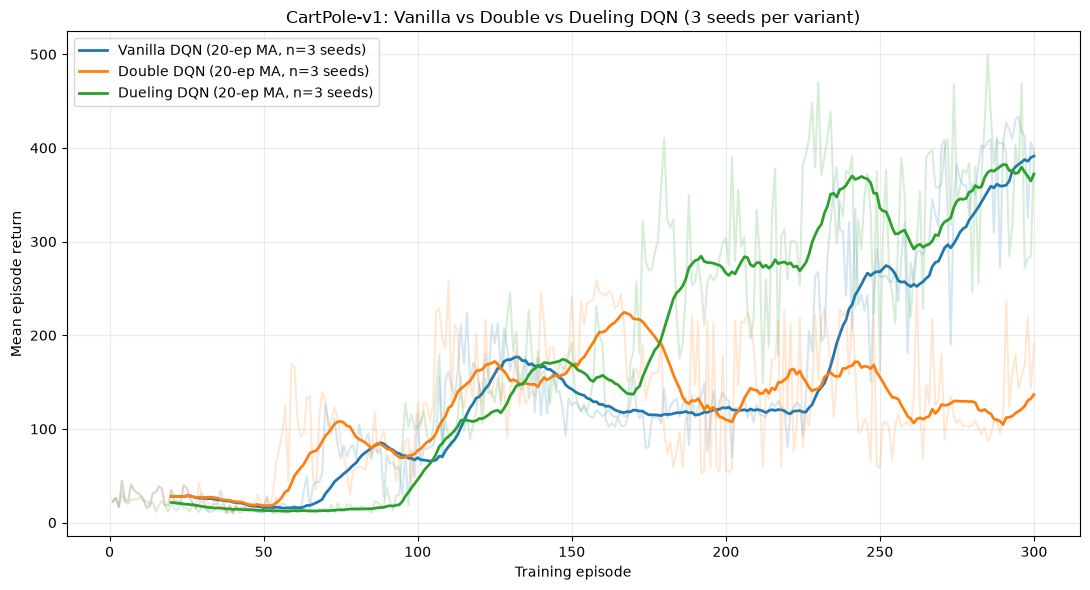

In [32]:
# Plot mean return of all variants
# The faint lines show unsmoothed mean episode returns. Bold lines show 20-episode moving averages of the mean. Both aggregate across three seeds.

def moving_average(x, window=20):
    return np.convolve(np.asarray(x, dtype=float), np.ones(window) / window, mode='valid')

fig, ax = plt.subplots(figsize=(11, 6))
for name in VARIANTS:
    returns = np.stack([results[name][seed]['returns'] for seed in SEEDS])
    mean_return = returns.mean(axis=0)
    x = np.arange(1, len(mean_return) + 1)
    line, = ax.plot(x[19:], moving_average(mean_return, 20), linewidth=2,
                    label=f'{name} (20-ep MA, n=3 seeds)')
    ax.plot(x, mean_return, alpha=0.18, color=line.get_color())
ax.set(xlabel='Training episode', ylabel='Mean episode return',
       title='CartPole-v1: Vanilla vs Double vs Dueling DQN (3 seeds per variant)')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('part2_variant_comparison.png', dpi=160)
plt.show()

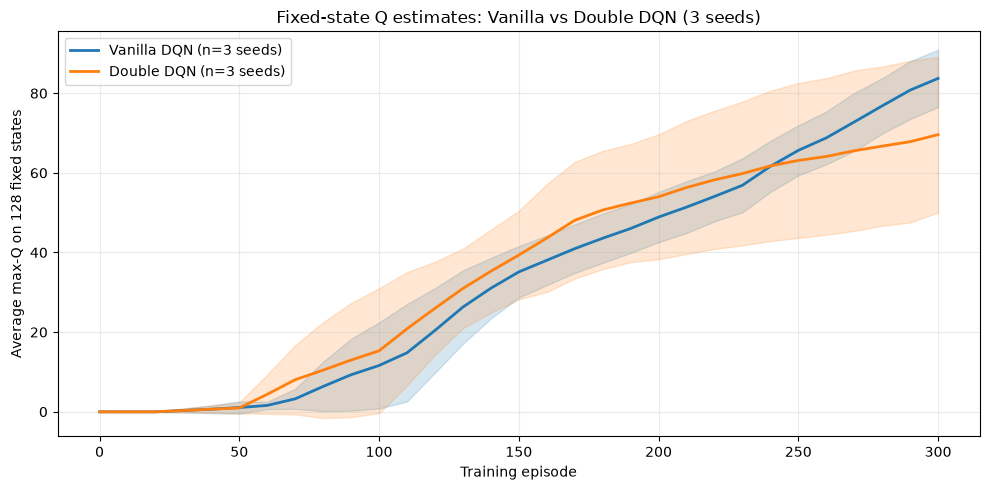

In [33]:
# Plot fixed-state average max-Q (Vanilla vs Double)
# Mean and standard deviation across three seeds are shown. A higher max-Q estimate is not by itself proof of overestimation.

fig, ax = plt.subplots(figsize=(10, 5))
for name in ('Vanilla DQN', 'Double DQN'):
    q = np.stack([results[name][seed]['q_values'] for seed in SEEDS])
    episodes = results[name][SEEDS[0]]['q_episodes']
    mean, std = q.mean(axis=0), q.std(axis=0)
    line, = ax.plot(episodes, mean, label=f'{name} (n=3 seeds)', linewidth=2)
    ax.fill_between(episodes, mean - std, mean + std,
                    color=line.get_color(), alpha=0.18)
ax.set(xlabel='Training episode', ylabel='Average max-Q on 128 fixed states',
       title='Fixed-state Q estimates: Vanilla vs Double DQN (3 seeds)')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('part2_max_q_comparison.png', dpi=160)
plt.show()


In [34]:
# Q5. Report metrics and identify the best variant
# The table uses the mean of each seed’s final 20 training returns, then averages those three means. It also reports each seed’s best 20-episode rolling mean. Do not claim which variant won before running.

summary = {}
for name in VARIANTS:
    final20 = [float(np.mean(results[name][seed]['returns'][-20:])) for seed in SEEDS]
    best20 = [float(np.max(moving_average(results[name][seed]['returns'], 20))) for seed in SEEDS]
    summary[name] = dict(final20_mean=float(np.mean(final20)),
                         final20_std=float(np.std(final20)),
                         best20_per_seed=best20)
    print(f'{name:14s} | final-20 mean (3 seeds)={np.mean(final20):7.2f} '
          f'± {np.std(final20):6.2f} | best20 per seed={np.round(best20, 1)}')
winner = max(summary, key=lambda name: summary[name]['final20_mean'])
print('\nBest by mean final-20 return:', winner)


Vanilla DQN    | final-20 mean (3 seeds)= 391.35 ± 107.24 | best20 per seed=[478.6 477.6 250. ]
Double DQN     | final-20 mean (3 seeds)= 136.70 ±  43.67 | best20 per seed=[443.8 213.2 226.4]
Dueling DQN    | final-20 mean (3 seeds)= 372.17 ±  69.02 | best20 per seed=[488.4 496.4 452.1]

Best by mean final-20 return: Vanilla DQN


**1. Which variant performed best?**

Vanilla DQN performed best with a final 20-episode mean return of **391.35 ± 107.24**, followed by Dueling DQN (**372.17 ± 69.02**) and Double DQN (**136.70 ± 43.67**). Vanilla and Dueling performed similarly, while Double DQN showed considerably lower final performance.

**2. Why might differences be small on CartPole?**

CartPole has only four state features and two actions, making it relatively simple. Vanilla DQN can already learn a strong policy, so advanced methods may offer limited improvements. Random seed variability can also affect results.

**3. What problem does Double DQN fix?**

Double DQN reduces **Q-value overestimation bias** by using the online network to select actions and the target network to evaluate them. This can improve learning stability but does not guarantee better performance.

**4. Fixed-state max-Q plot**

The plot compares Vanilla and Double DQN's estimated maximum Q-values during training. Differences may suggest overestimation, but confirming it requires comparison with actual return estimates. The higher curve and consistency of the gap must be determined from the plot.

# Part 3: Pixels and Wrap-Up (Atari), 30 pts

Use Pong (PongNoFrameskip-v4). You are not expected to master Pong in this time; the goal is to build and sanity-check the pixel pipeline.

1. Build the preprocessing pipeline: frame skip of 4 with max-pooling, grayscale, 84×84 resize, and a stack of 4 frames. Library wrappers are allowed, but add a one-line comment explaining each step. (6 pts)
2. Implement the CNN Q-network: a 32-filter 8×8 convolution with stride 4, a 64-filter 4×4 convolution with stride 2, a 64-filter 3×3 convolution with stride 1, a 512-unit dense layer, and one output per action. (6 pts)
3. Print the observation shape (4, 84, 84) and the network's output shape. Then train for at least 50,000 environment steps with your replay buffer, and plot the loss and the episode reward next to a random-agent baseline. (8 pts)
4. Logbook: Explain why Atari DQN uses frame stacking, frame skipping, and reward clipping. (5 pts)
5. Wrap-up: In 2-3 sentences, say what instability experience replay fixes and what a target network fixes. (3 pts)
6. Wrap-up: In 1-2 sentences, say why a dueling head helps when many actions have similar value. (2 pts)


In [42]:
# Atari Pong: Pixel DQN

%pip install -U "gymnasium[atari,accept-rom-license]"

Note: you may need to restart the kernel to use updated packages.


In [41]:
%pip install ale-py autorom torch numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [45]:
%pip install "gymnasium[other]"

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 16.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.0/68.0 MB 42.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 48.7 MB/s eta 0:00:00:00:0100:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
  Attempting uninstall: pillow0m━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/8 [proglog]
   ━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/8 [proglog]    WARNING: Ignoring invalid distribution ~ransformers (/home/cse/anaconda3/envs/python312/lib/python3.12/site-packages)
    Found existing installation: pillow 13.0.0
    Uninstalling pillow-13.0.0:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/8 [proglog]
      Successfully uninstalled pillow-13.0.0━━━━━━━━━━━━━━━━━━ 1/8 [proglog]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [moviepy]m7/8 [moviepy]ffmpeg]
Note: you may need to restart the kernel to use updated packages.


In [46]:
import random, collections
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import gymnasium as gym
import ale_py
from gymnasium.wrappers import AtariPreprocessing, FrameStackObservation

gym.register_envs(ale_py)
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cpu


In [47]:
# Preprocessing
# The fallback uses the equivalent modern ALE Pong environment with internal frame skipping disabled to avoid repeating frames twice.

def make_pong(seed=42):
    try:
        # Prefer the exact legacy environment requested, when registered.
        env = gym.make('PongNoFrameskip-v4')
        name = 'PongNoFrameskip-v4'
    except (gym.error.Error, gym.error.NameNotFound, gym.error.NamespaceNotFound):
        # Modern replacement: disable built-in frame skipping (the wrapper handles it).
        env = gym.make('ALE/Pong-v5', frameskip=1, repeat_action_probability=0.0)
        name = 'ALE/Pong-v5 (frameskip=1)'
    # Repeat each action 4 emulator frames; max-pool last two to reduce flicker.
    # Convert RGB to grayscale and resize each processed frame to 84 x 84.
    env = AtariPreprocessing(env, noop_max=30, frame_skip=4,
                             screen_size=84, grayscale_obs=True,
                             scale_obs=False, terminal_on_life_loss=False)
    # Stack 4 successive processed frames to provide motion information.
    env = FrameStackObservation(env, stack_size=4)
    env.action_space.seed(seed)
    return env, name

env, env_name = make_pong(SEED)
obs, _ = env.reset(seed=SEED)
print('Environment:', env_name)
print('Observation shape:', obs.shape)
print('Observation dtype:', obs.dtype)
print('Actions:', env.action_space.n)
assert obs.shape == (4, 84, 84)
assert obs.dtype == np.uint8

Environment: PongNoFrameskip-v4
Observation shape: (4, 84, 84)
Observation dtype: uint8
Actions: 6


In [48]:
# CNN Q-network
# Normalize uint8 pixels to [0,1] inside the forward pass.

class AtariQNetwork(nn.Module):
    def __init__(self, n_actions):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(4, 32, kernel_size=8, stride=4), nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1), nn.ReLU(),
            nn.Flatten(),
        )
        self.head = nn.Sequential(nn.Linear(64 * 7 * 7, 512), nn.ReLU(),
                                  nn.Linear(512, n_actions))

    def forward(self, x):
        return self.head(self.features(x.float() / 255.0))

online = AtariQNetwork(env.action_space.n).to(DEVICE)
target = AtariQNetwork(env.action_space.n).to(DEVICE)
target.load_state_dict(online.state_dict())
with torch.no_grad():
    out = online(torch.as_tensor(np.asarray(obs)[None], device=DEVICE))
print('Network output shape:', tuple(out.shape))
assert out.shape == (1, env.action_space.n)

Network output shape: (1, 6)


In [49]:
# Replay buffer, random baseline, and 50,000-step training (8 pts)
# This buffer stores both observations and next observations as uint8. Capacity 3,000 uses about 127 MB for image arrays; increase only if sufficient RAM is available. For a stronger agent, longer training and a larger replay buffer are typically needed.

class PixelReplayBuffer:
    def __init__(self, capacity=3000):
        self.capacity = capacity
        self.states = np.empty((capacity, 4, 84, 84), dtype=np.uint8)
        self.next_states = np.empty_like(self.states)
        self.actions = np.empty(capacity, dtype=np.int64)
        self.rewards = np.empty(capacity, dtype=np.float32)
        self.terminated = np.empty(capacity, dtype=np.float32)
        self.size = self.pos = 0

    def add(self, state, action, reward, next_state, terminated):
        i = self.pos
        self.states[i] = state
        self.next_states[i] = next_state
        self.actions[i] = action
        self.rewards[i] = reward
        self.terminated[i] = terminated
        self.pos = (i + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size, device):
        idx = np.random.randint(self.size, size=batch_size)
        return (torch.as_tensor(self.states[idx], device=device),
                torch.as_tensor(self.actions[idx], device=device),
                torch.as_tensor(self.rewards[idx], device=device),
                torch.as_tensor(self.next_states[idx], device=device),
                torch.as_tensor(self.terminated[idx], device=device))

buffer = PixelReplayBuffer(capacity=3000)


In [50]:
def random_baseline(n_episodes=5, seed=1000):
    e, _ = make_pong(seed)
    episode_rewards = []
    for ep in range(n_episodes):
        state, _ = e.reset(seed=seed + ep)
        done = False
        total = 0.0
        while not done:
            state, reward, terminated, truncated, _ = e.step(e.action_space.sample())
            total += reward
            done = terminated or truncated
        episode_rewards.append(total)
    e.close()
    return episode_rewards

random_rewards = random_baseline()
print('Random baseline rewards:', random_rewards)
print('Random baseline mean:', np.mean(random_rewards))

Random baseline rewards: [-21.0, -20.0, -21.0, -21.0, -20.0]
Random baseline mean: -20.6


In [51]:
TOTAL_STEPS = 50_000
LEARNING_STARTS = 2_000
TRAIN_FREQ = 4
TARGET_UPDATE = 1_000
BATCH_SIZE = 32
GAMMA = 0.99
EPS_START, EPS_END = 1.0, 0.1
EPS_DECAY_STEPS = 40_000
optimizer = torch.optim.Adam(online.parameters(), lr=1e-4)
losses, loss_steps = [], []
episode_rewards, episode_end_steps = [], []
state, _ = env.reset(seed=SEED)
episode_return = 0.0

def choose_action(state, epsilon):
    if np.random.random() < epsilon:
        return env.action_space.sample()
    with torch.no_grad():
        x = torch.as_tensor(np.asarray(state)[None], device=DEVICE)
        return int(online(x).argmax(dim=1).item())

for step in range(1, TOTAL_STEPS + 1):
    epsilon = EPS_END + (EPS_START - EPS_END) * max(0.0, 1 - step / EPS_DECAY_STEPS)
    action = choose_action(state, epsilon)
    next_state, reward, terminated, truncated, _ = env.step(action)
    done = terminated or truncated
    # Clip learning rewards to [-1, 1], but track original rewards for reporting.
    buffer.add(np.asarray(state), action, np.clip(reward, -1, 1),
               np.asarray(next_state), terminated)
    episode_return += reward
    state = next_state

    if step >= LEARNING_STARTS and step % TRAIN_FREQ == 0 and buffer.size >= BATCH_SIZE:
        s, a, r, ns, term = buffer.sample(BATCH_SIZE, DEVICE)
        q = online(s).gather(1, a[:, None]).squeeze(1)
        with torch.no_grad():
            next_q = target(ns).max(dim=1).values
            y = r + GAMMA * (1.0 - term) * next_q
        loss = F.smooth_l1_loss(q, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(online.parameters(), max_norm=10.0)
        optimizer.step()
        losses.append(float(loss.item()))
        loss_steps.append(step)

    if step % TARGET_UPDATE == 0:
        target.load_state_dict(online.state_dict())

    if done:
        episode_rewards.append(episode_return)
        episode_end_steps.append(step)
        state, _ = env.reset()
        episode_return = 0.0

    if step % 5_000 == 0:
        recent = np.mean(episode_rewards[-5:]) if episode_rewards else float('nan')
        print(f'Step {step:6d}/{TOTAL_STEPS} | eps={epsilon:.3f} | '
              f'episodes={len(episode_rewards)} | last-5 return={recent:.2f}')

env.close()
print('Completed environment steps:', TOTAL_STEPS)
print('Completed episodes:', len(episode_rewards))


Step   5000/50000 | eps=0.887 | episodes=5 | last-5 return=-20.80
Step  10000/50000 | eps=0.775 | episodes=11 | last-5 return=-20.60
Step  15000/50000 | eps=0.662 | episodes=17 | last-5 return=-20.40
Step  20000/50000 | eps=0.550 | episodes=22 | last-5 return=-19.80
Step  25000/50000 | eps=0.438 | episodes=27 | last-5 return=-20.80
Step  30000/50000 | eps=0.325 | episodes=33 | last-5 return=-20.80
Step  35000/50000 | eps=0.213 | episodes=39 | last-5 return=-20.80
Step  40000/50000 | eps=0.100 | episodes=45 | last-5 return=-21.00
Step  45000/50000 | eps=0.100 | episodes=52 | last-5 return=-20.60
Step  50000/50000 | eps=0.100 | episodes=58 | last-5 return=-20.80
Completed environment steps: 50000
Completed episodes: 58


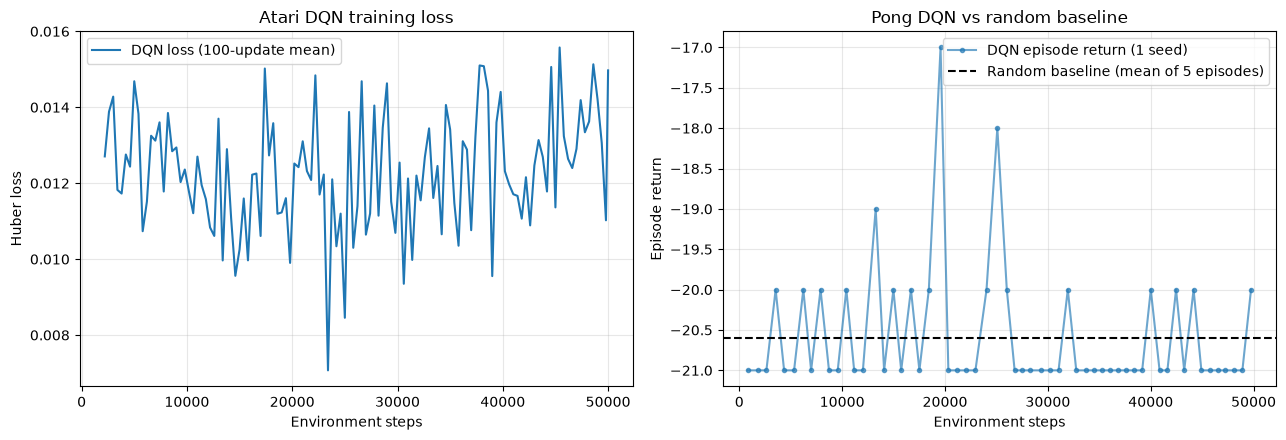

In [52]:
#Training plots
#Loss is averaged in blocks of 100 optimizer updates. Episode rewards are plotted at the environment step when each episode ends. The random baseline is a horizontal mean across five complete random-policy episodes.

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
if losses:
    k = 100
    xs = [np.mean(loss_steps[i:i+k]) for i in range(0, len(losses), k)]
    ys = [np.mean(losses[i:i+k]) for i in range(0, len(losses), k)]
    axes[0].plot(xs, ys, label='DQN loss (100-update mean)')
axes[0].set(xlabel='Environment steps', ylabel='Huber loss', title='Atari DQN training loss')
axes[0].legend(); axes[0].grid(alpha=0.3)
if episode_rewards:
    axes[1].plot(episode_end_steps, episode_rewards, marker='.', alpha=0.65,
                 label='DQN episode return (1 seed)')
axes[1].axhline(np.mean(random_rewards), color='black', linestyle='--',
                label=f'Random baseline (mean of {len(random_rewards)} episodes)')
axes[1].set(xlabel='Environment steps', ylabel='Episode return', title='Pong DQN vs random baseline')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig('part3_atari_training.png', dpi=180, bbox_inches='tight')
plt.show()


### Q4 — Logbook: Atari Preprocessing (5 pts)

Frame stacking combines four consecutive frames, allowing the DQN to understand motion, such as the direction and speed of the ball. Frame skipping repeats the same action for four frames, reducing computational cost, while max-pooling the last two frames reduces flickering. Reward clipping limits reward values to a fixed range, helping stabilize Q-learning by preventing large rewards from producing excessively large TD targets.

### Q5 — Wrap-up: Replay and Target Networks (3 pts)

Experience replay stores past transitions and randomly samples them during training, reducing correlations between consecutive experiences and improving training stability. The target network provides more stable Q-value targets by keeping its parameters fixed for several training steps before updating them from the main network.

### Q6 — Wrap-up: Dueling Head (2 pts)

A dueling network separates Q-value estimation into two components: state value and action advantage. This allows the model to learn how valuable a state is independently of the specific action selected. It can improve learning when multiple actions have similar effects.

### Results Note

The DQN agent completed **50,000 environment steps and 58 episodes** on Atari Pong.

The random-agent baseline obtained episode rewards of **[-21, -20, -21, -21, -20]**, giving a mean reward of **−20.60**.

The DQN's final five-episode average reward was **−20.80**, which was slightly lower than the random baseline by **0.20 points**.

The episode reward logs show fluctuations between approximately −21 and −19, without a consistent improvement over training. This suggests that the DQN had not yet learned an effective Pong-playing policy.

The training loss was recorded for analysis, but its trend cannot be confirmed without inspecting the loss plot.

Overall, the experiment completed the required 50,000 training steps and provided a sanity check of the Atari preprocessing and DQN training pipeline. However, the agent did not outperform the random baseline. More training steps and hyperparameter tuning may be required to achieve better performance.

## Deliverables, grading and hints

Submit one Jupyter notebook containing code, plots and logbook answers in markdown cells.

1. Fix random seeds so results are reproducible.
2. Label every plot with axes, a legend, and the number of seeds averaged.
3. If the Part 3 training output is too long, keep the plots and attach the log separately.

Grading criterion: Weight
Correct implementations: 50%
Plots and experiment quality: 20%
Logbook explanations: 25%
Code clarity: 5%

#### Hints

Part 1: compute target values without gradients, zero the future term on terminal transitions, and start learning only after the buffer holds a few thousand transitions.

Part 2: vanilla and Double DQN differ in one line of the target. In the dueling head, subtract the mean advantage.

Part 3: store frames as uint8 and divide by 255 inside the network, and keep the buffer to 50,000 transitions or fewer so it fits in memory. Install gymnasium[atari] and accept the ROM license.
